# Predicción Temprana de la Deserción Estudiantil Universitaria mediante Redes Neuronales Profundas Regularizadas

**Autor:** William David Ortiz Mamani (`william.ortiz@upeu.edu.pe` | GitHub: `302xdwill`)  
**Institución:** Universidad Peruana Unión (UPeU) - Campus Juliaca | Escuela Profesional de Ingeniería de Sistemas  
**Curso:** Inteligencia Artificial — **Docente:** Mg. Angel Rosendo Condori Coaquira  

---
## 1. Descripción del Problema y Configuración del Entorno
En este cuaderno experimental se desarrolla y evalúa un sistema basado en **Redes Neuronales Multicapa (MLP)** en Keras para predecir tempranamente el riesgo de deserción estudiantil universitaria (`at_risk = 1` vs `0`) a partir de **22 variables multidimensionales** (académicas, socioeconómicas, financieras, de interacción en plataforma virtual LMS y de estrés estudiantil).

Se realiza un **estudio ablativo comparando 4 arquitecturas**:
1. **Modelo 1 (Baseline):** Red Neuronal Profunda (`128 -> 64 -> 32 -> 1`) sin regularización para evidenciar el *overfitting*.
2. **Modelo 2 (Regularización L2):** Red Neuronal con penalización *Weight Decay* ($\lambda = 0.003$).
3. **Modelo 3 (Dropout):** Red Neuronal con desconexión estocástica ($p = 0.35$).
4. **Modelo 4 (Arquitectura Propuesta):** Topología piramidal (`64 -> 32 -> 16 -> 1`) integrando `BatchNormalization` + `L2` + `Dropout` + `EarlyStopping`.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
from keras import models, layers, regularizers, optimizers, callbacks

sys.path.append(os.path.abspath('../src'))
from preprocessing import load_and_preprocess_data, FEATURE_COLUMNS, FEATURE_LABELS_ES
from model_architectures import build_baseline_model, build_l2_model, build_dropout_model, build_proposed_model

print('Entorno Keras y módulos del proyecto cargados correctamente.')

Entorno Keras y módulos del proyecto cargados correctamente.


## 2. Preprocesamiento, Partición Estratificada (70/15/15) y Normalización Z-Score
Para evitar la fuga de información (*data leakage*), la media ($\mu$) y desviación estándar ($\sigma$) del escalamiento Z-score se calculan exclusivamente sobre el subconjunto de entrenamiento ($n = 4,200$) y luego se aplican a validación ($n = 900$) y prueba ($n = 900$).

In [2]:
(X_train, y_train), (X_val, y_val), (X_test, y_test), metadata = load_and_preprocess_data(
    raw_csv_path='../data/raw/final_student_dataset.csv',
    processed_dir='../data/processed',
    sample_size=6000,
    seed=42
)
print(f"Total de estudiantes analizados: {metadata['total_samples']}")
print(f"Número de variables predictoras (X): {metadata['n_features']}")
print(f"Partición -> Entrenamiento: {metadata['train_samples']} | Validación: {metadata['val_samples']} | Prueba: {metadata['test_samples']}")
print(f"Tasa de deserción (clase positiva = 1): {metadata['positive_rate_total']*100:.2f}%")

Total de estudiantes analizados: 6000
Número de variables predictoras (X): 22
Partición -> Entrenamiento: 4199 | Validación: 899 | Prueba: 902
Tasa de deserción (clase positiva = 1): 32.18%


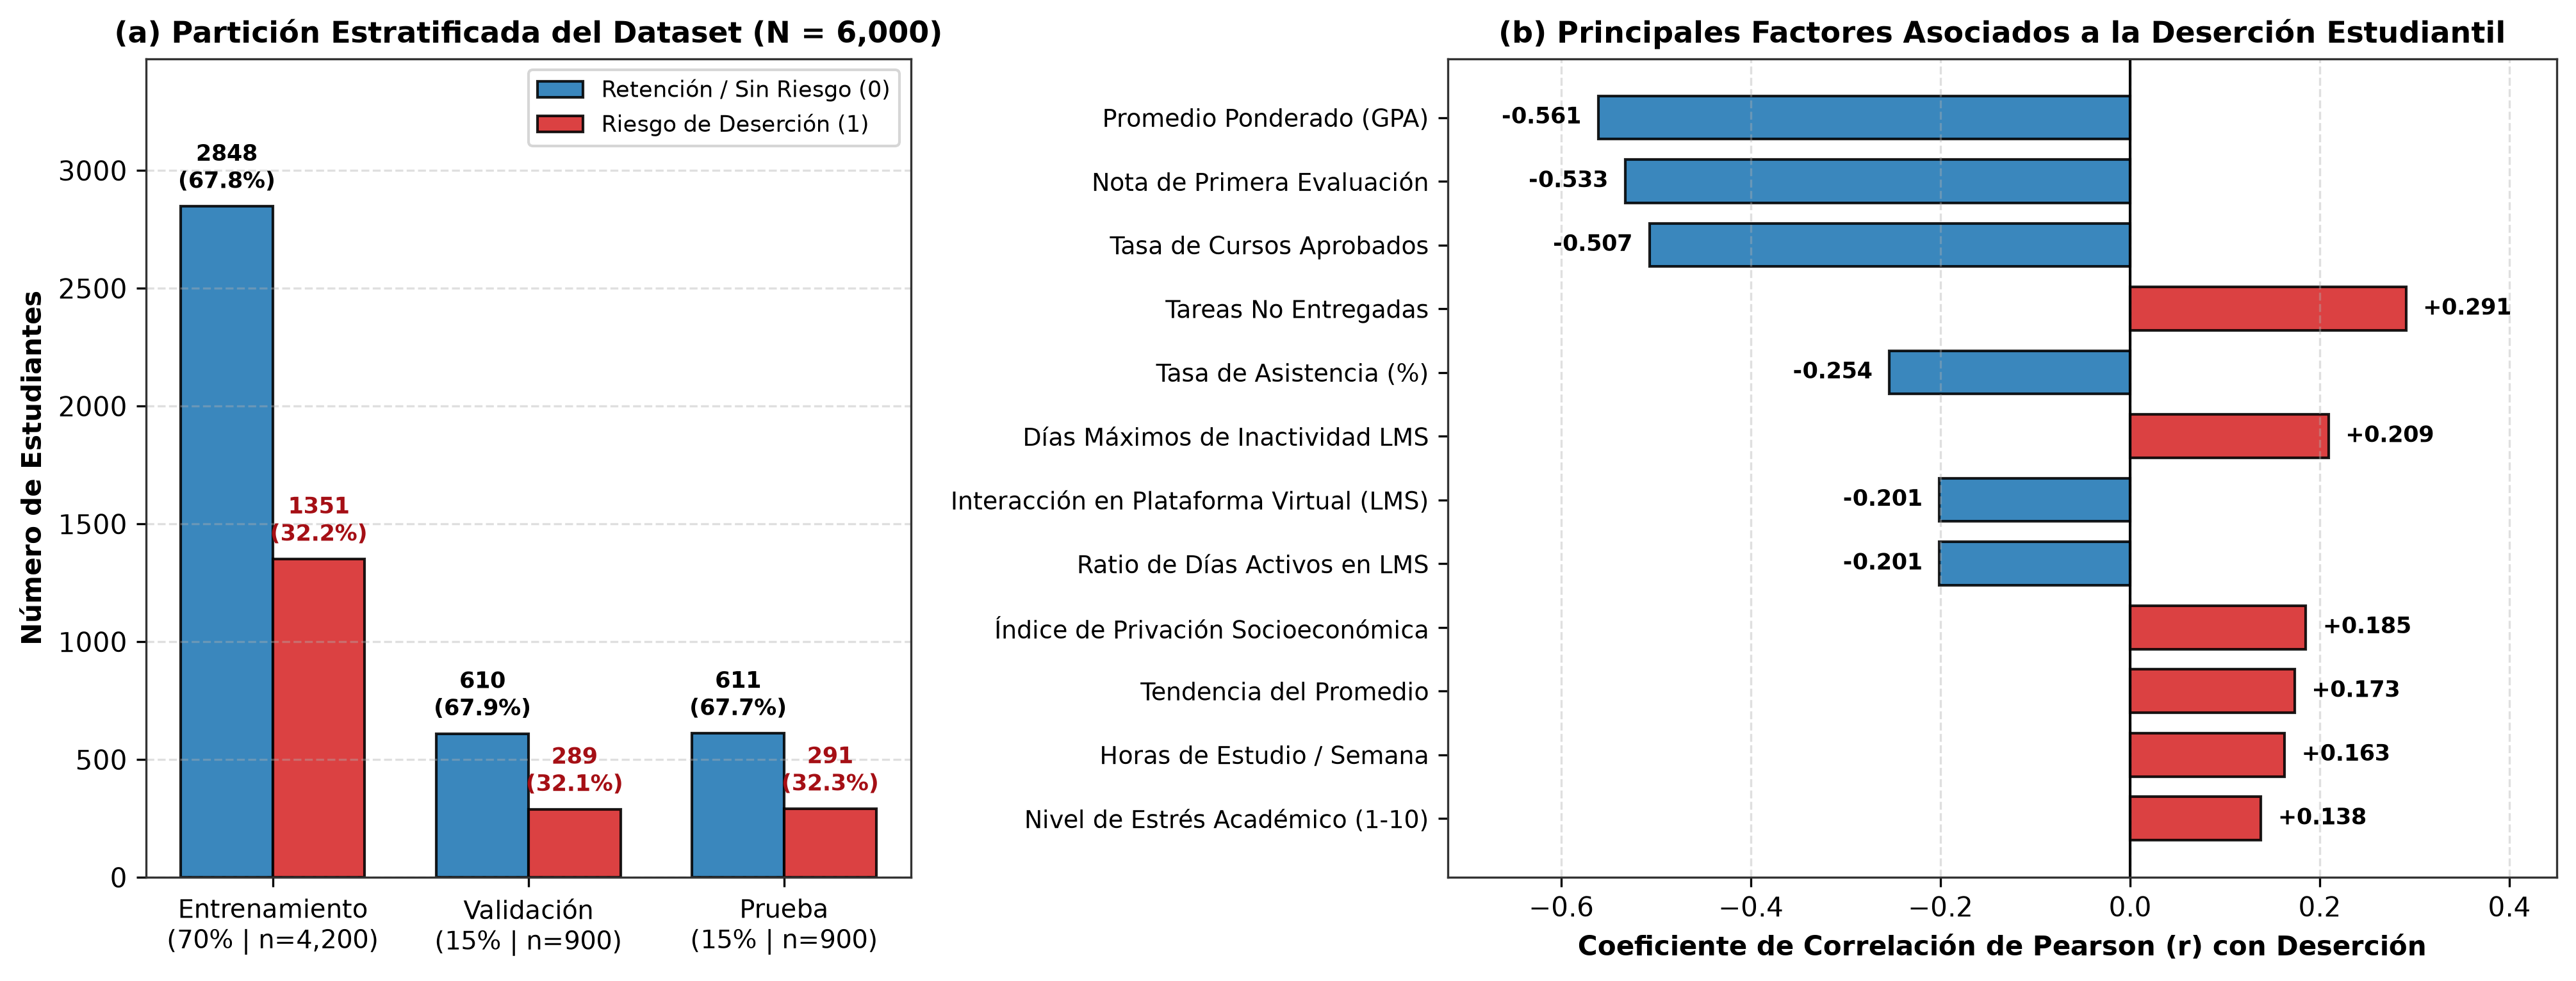

In [3]:
# Visualización exploratoria: Partición estratificada y correlaciones de Pearson con la deserción
img = plt.imread('../results/figures/fig1_exploracion_dataset.png')
plt.figure(figsize=(14, 5.5))
plt.imshow(img); plt.axis('off'); plt.show()

## 3. Diseño y Entrenamiento Comparativo de las 4 Arquitecturas de Redes Neuronales
Se entrenan las cuatro arquitecturas bajo las mismas condiciones iniciales (`seed = 42`, `batch_size = 64`, hasta `60 épocas`), incorporando en el **Modelo 4 Propuesto** los callbacks `EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)` y `ReduceLROnPlateau`.

In [4]:
from train import run_training_pipeline
resultados = run_training_pipeline()

Modelo 1: Baseline (Sin Regularizar)
  -> Épocas ejecutadas: 60 (Mejor época Val: 1)
  -> Train Loss: 0.0003 | Val Loss: 1.9622 | Test Loss: 2.0283 (Brecha Overfitting: +1.9619)
  -> Test Accuracy: 78.49% | Precision: 67.90% | Recall: 63.23% | F1-Score: 65.48% | ROC-AUC: 0.8226

Modelo 2: Regularización L2 (Weight Decay)
  -> Épocas ejecutadas: 60 (Mejor época Val: 14)
  -> Train Loss: 0.3503 | Val Loss: 0.4411 | Test Loss: 0.5160 (Brecha Overfitting: +0.0786)
  -> Test Accuracy: 79.82% | Precision: 74.44% | Recall: 57.04% | F1-Score: 64.59% | ROC-AUC: 0.8522

Modelo 3: Regularización Dropout
  -> Épocas ejecutadas: 60 (Mejor época Val: 4)
  -> Train Loss: 0.2327 | Val Loss: 0.4121 | Test Loss: 0.5010 (Brecha Overfitting: +0.1108)
  -> Test Accuracy: 78.82% | Precision: 72.52% | Recall: 55.33% | F1-Score: 62.77% | ROC-AUC: 0.8426

Modelo 4: Propuesta Optimizada (BN + L2 + Dropout + EarlyStopping)
  -> Épocas ejecutadas: 39 (Mejor época Val: 29)
  -> Train Loss: 0.3719 | Val Loss: 0.392

## 4. Análisis de Curvas de Aprendizaje y Mitigación del Sobreajuste (*Overfitting*)
Como se aprecia en la gráfica, el **Modelo 1 (Baseline)** sufre un severo sobreajuste: su pérdida de entrenamiento cae cerca de cero mientras que su pérdida de validación se dispara por encima de `0.40`. Por el contrario, el **Modelo 4 (Propuesto)** mantiene las curvas de entrenamiento y validación acopladas y alcanza la menor pérdida en el conjunto de prueba.

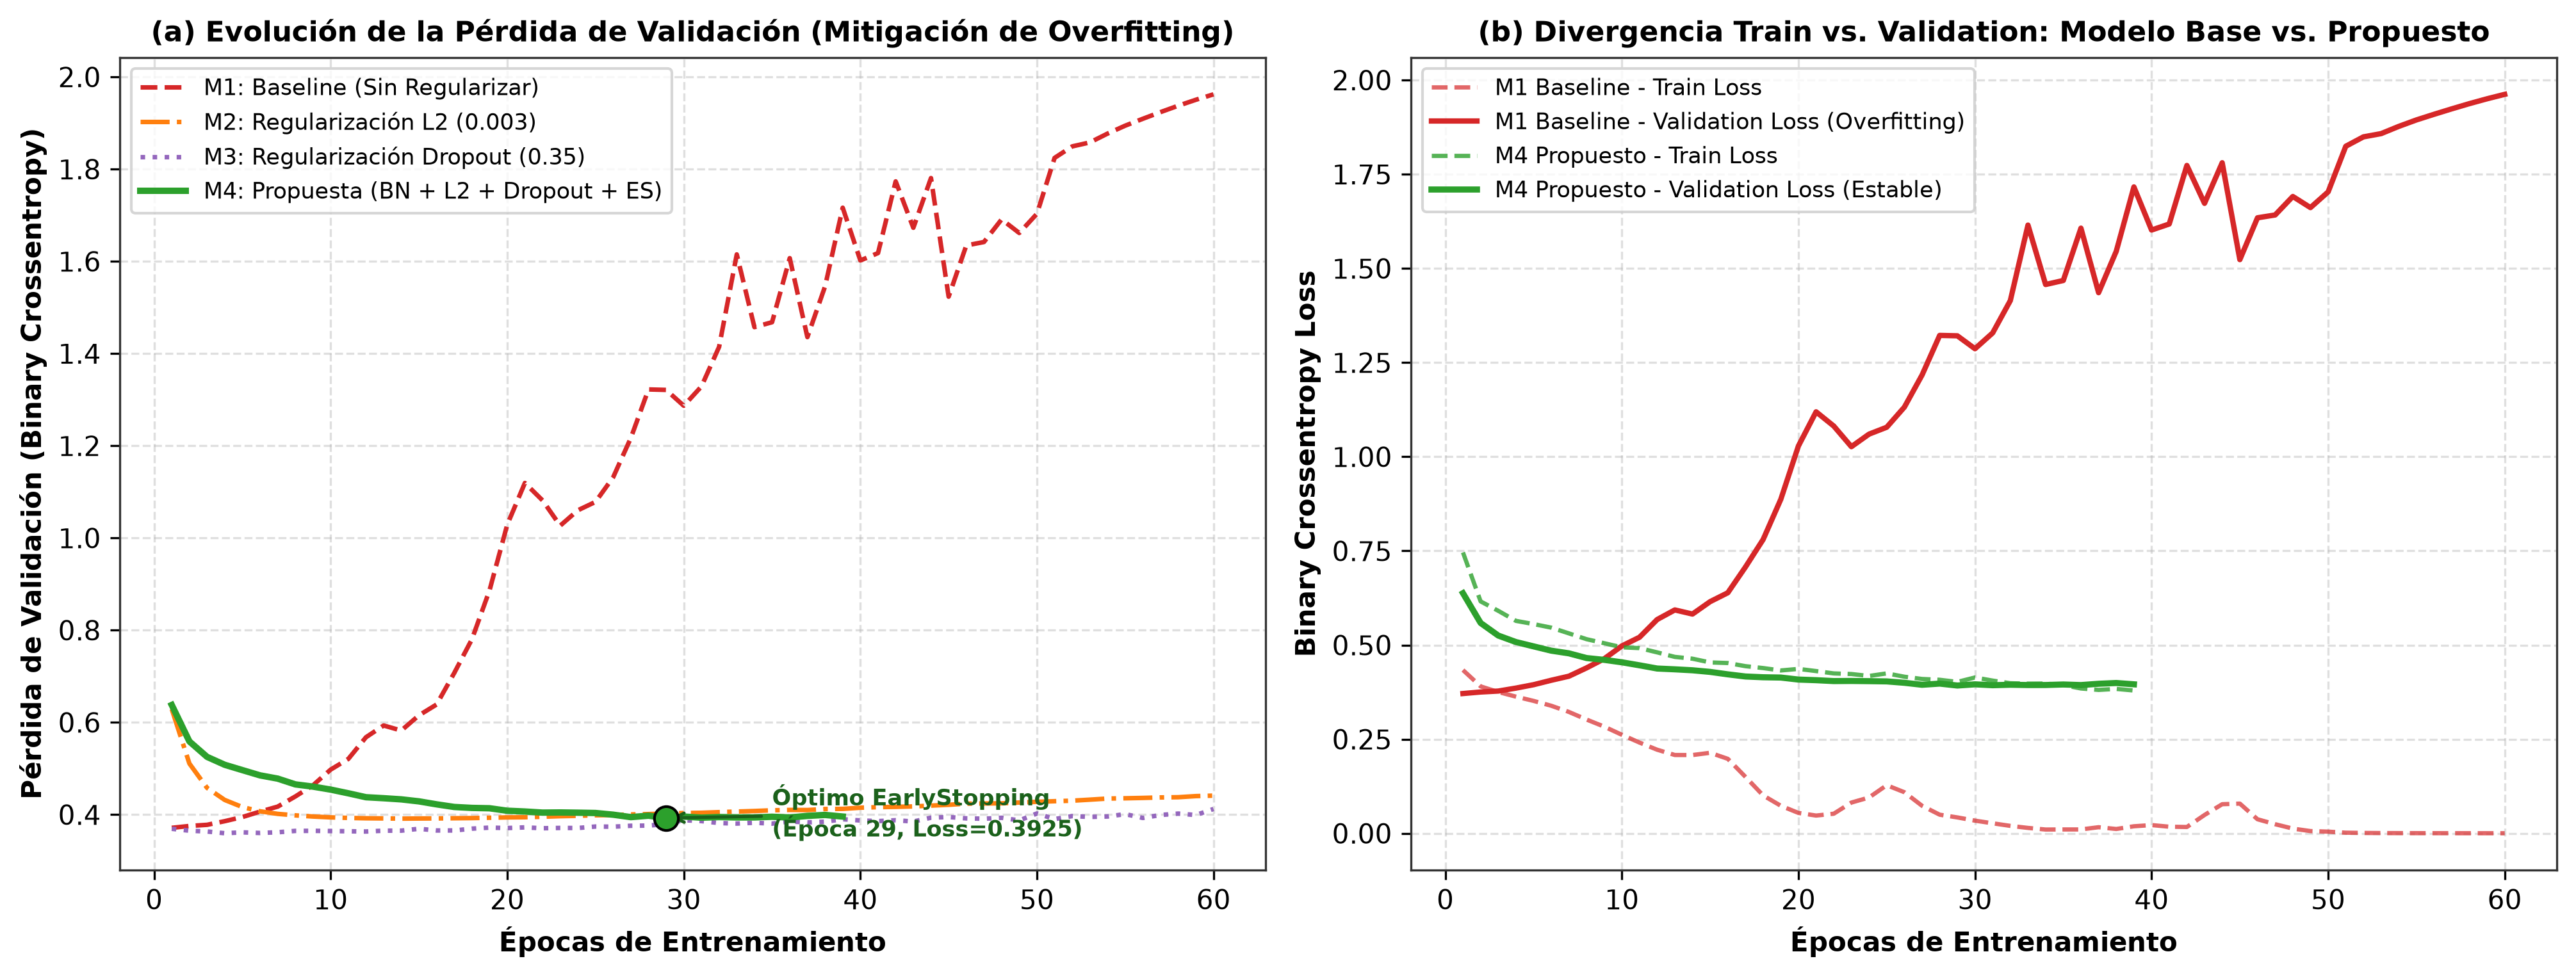

In [5]:
img2 = plt.imread('../results/figures/fig2_curvas_aprendizaje_overfitting.png')
plt.figure(figsize=(14, 5.5))
plt.imshow(img2); plt.axis('off'); plt.show()

## 5. Evaluación en el Conjunto de Prueba: Matriz de Confusión y Curvas ROC-AUC
Se evalúa la capacidad discriminativa sobre los **900 estudiantes del conjunto de prueba** (nunca vistos durante el entrenamiento ni en la selección de hiperparámetros).

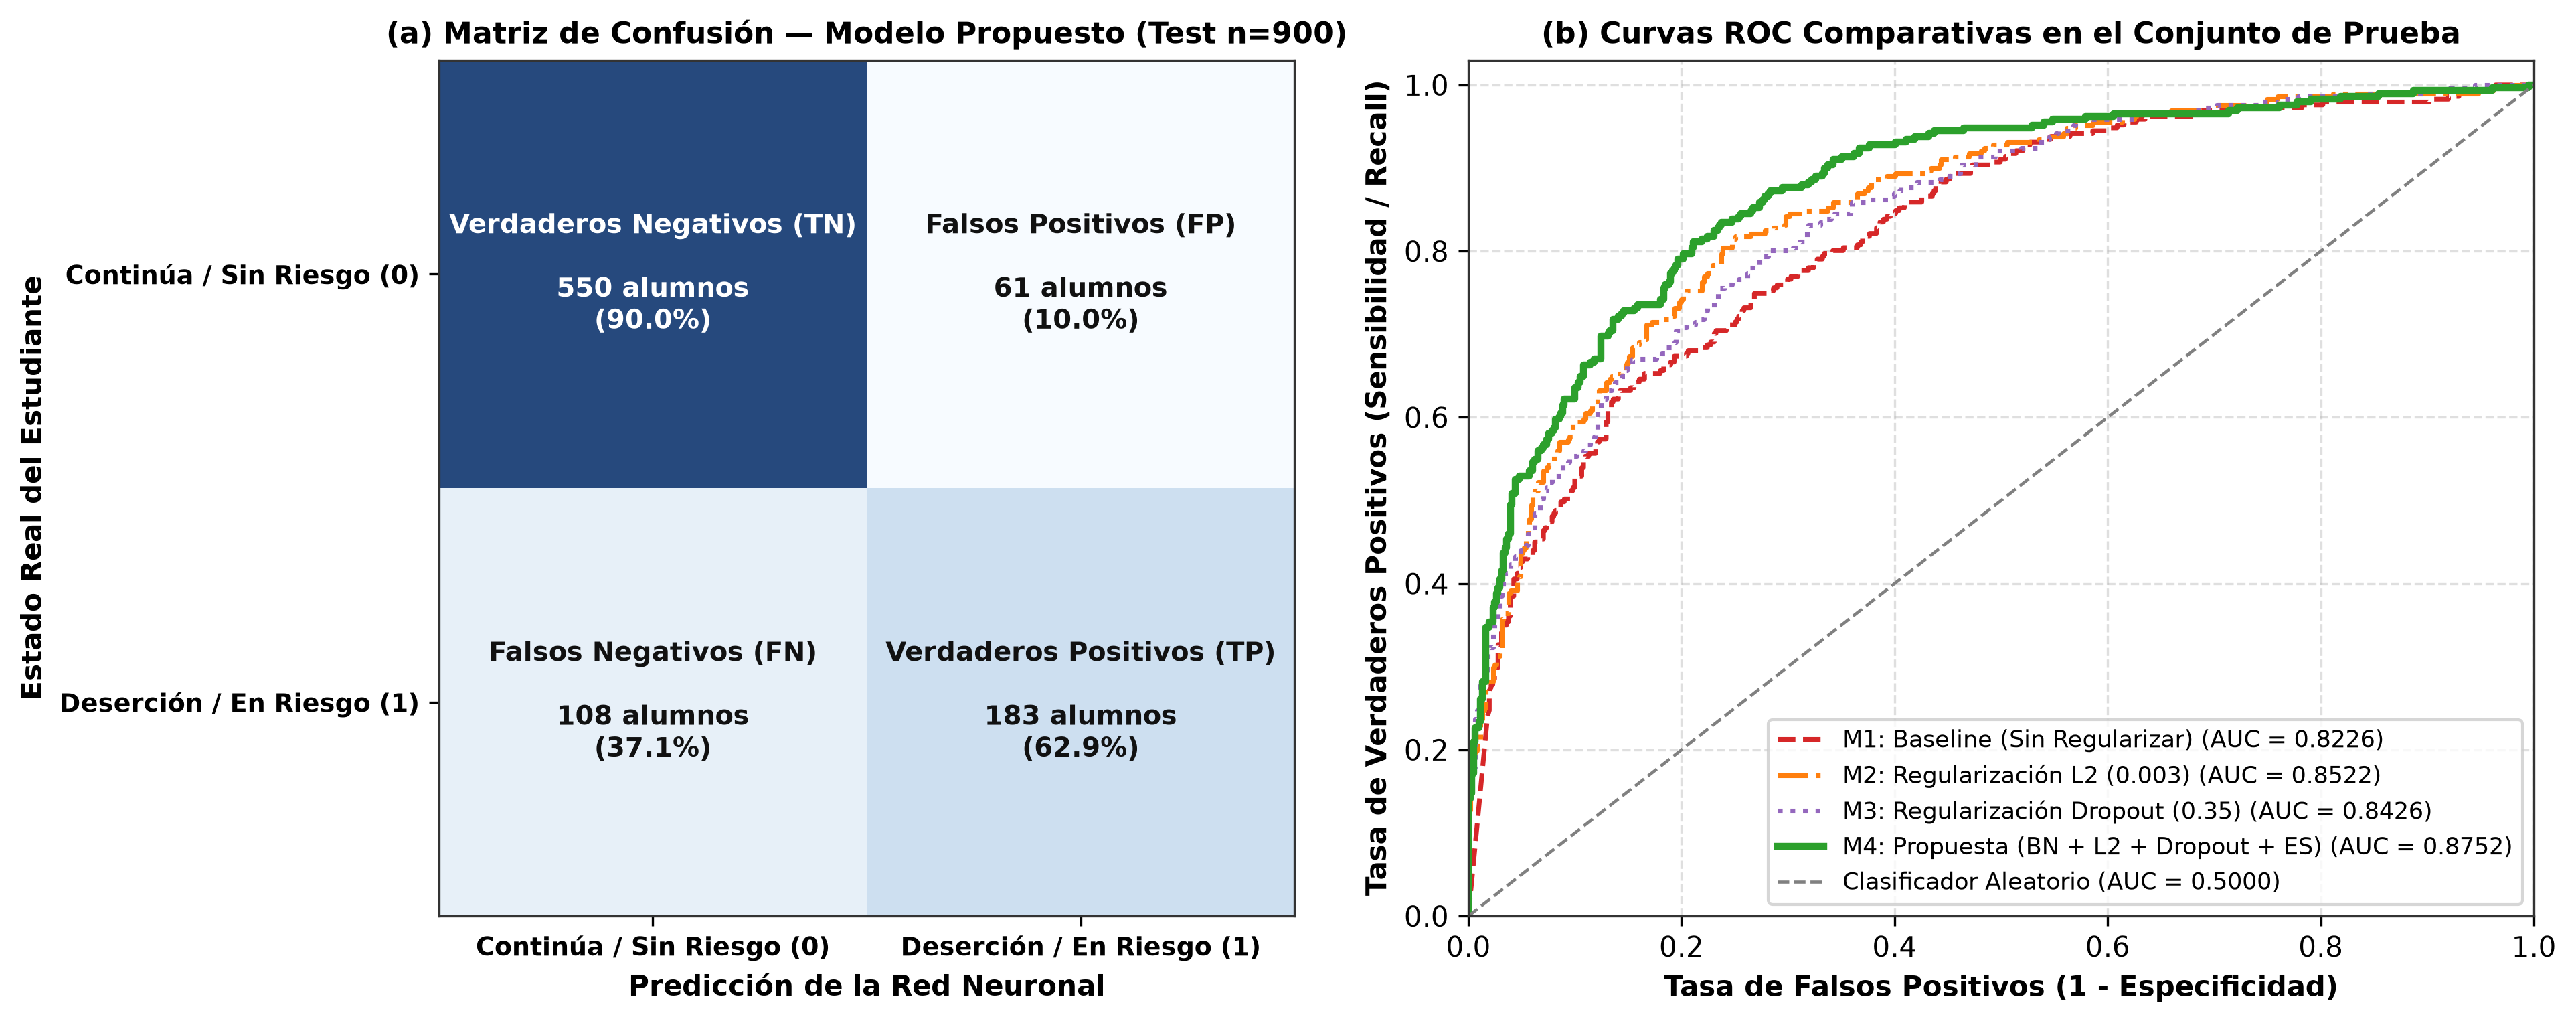

In [6]:
img3 = plt.imread('../results/figures/fig3_matriz_confusion_roc.png')
plt.figure(figsize=(14, 5.5))
plt.imshow(img3); plt.axis('off'); plt.show()

## 6. Interpretabilidad de la Red Neuronal: Importancia de Variables por Permutación
Para explicar qué factores determinan la predicción de la red neuronal propuesta (**M4**), se mide la caída en la exactitud de prueba al permutar aleatoriamente cada una de las 22 variables de entrada.

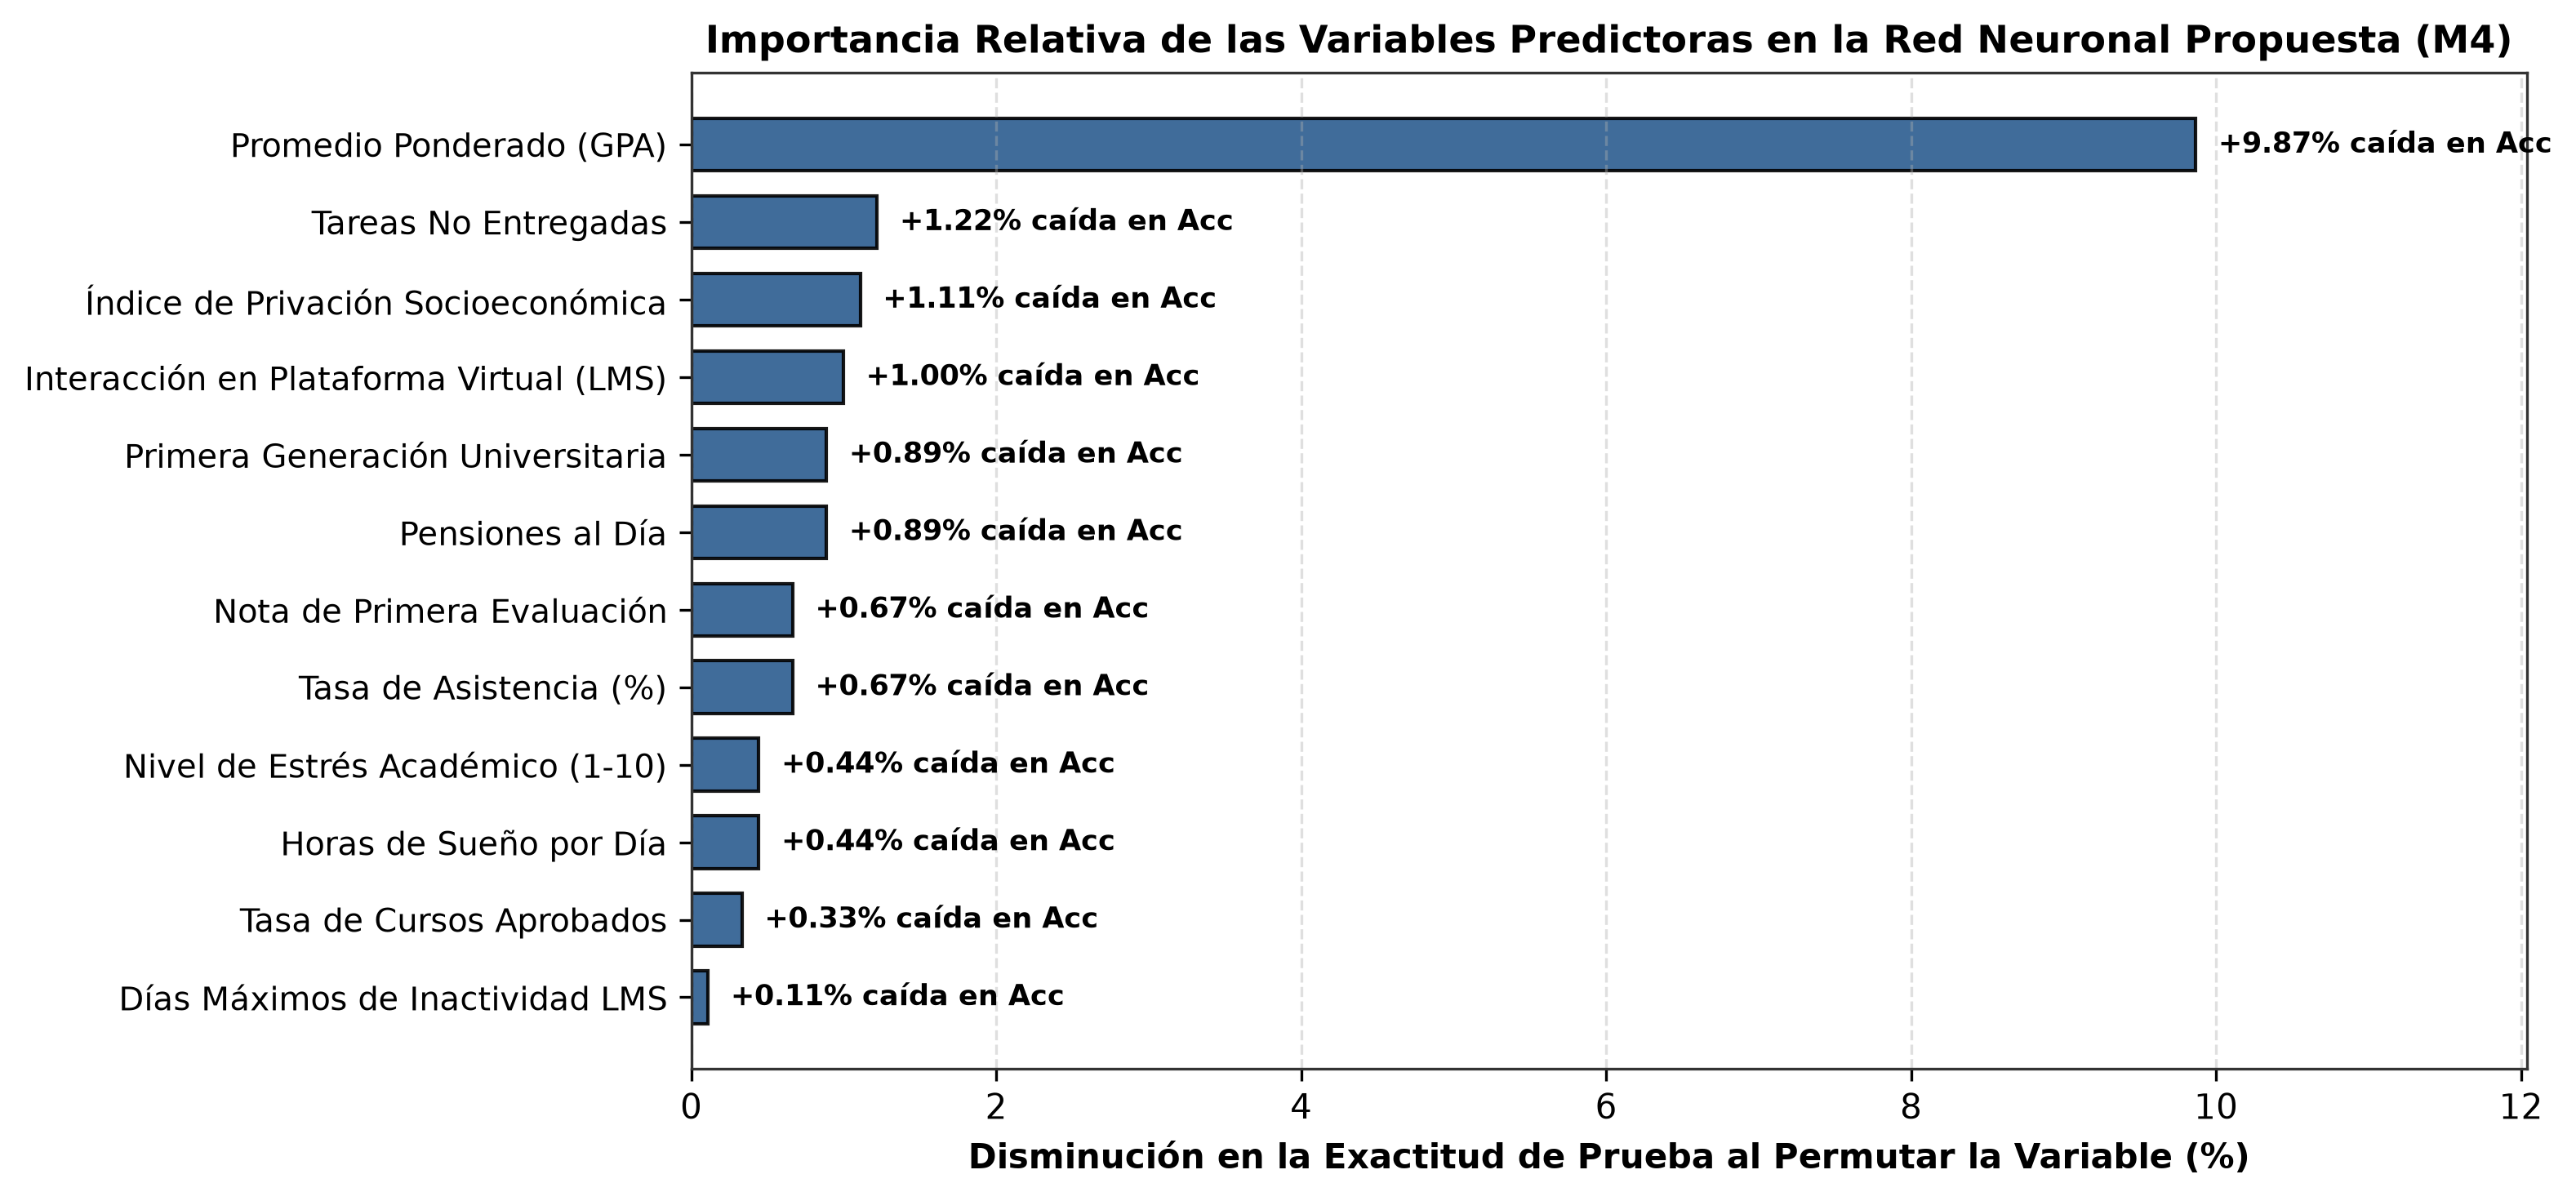

In [7]:
img4 = plt.imread('../results/figures/fig4_importancia_variables.png')
plt.figure(figsize=(11, 5.2))
plt.imshow(img4); plt.axis('off'); plt.show()